<a href="https://colab.research.google.com/github/kamilabalabatyr/AI-Fundamentals/blob/main/24B031683_Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math, random, time, os, itertools, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 3)

## 1. Load and visualize the locations
The file is in TSPLIB format. The rows under `NODE_COORD_SECTION` are `ID x y`.

In [ ]:
URL = "https://www.math.uwaterloo.ca/tsp/world/dj38.tsp"
FILE = "dj38.tsp"
if not os.path.exists(FILE):
    urllib.request.urlretrieve(URL, FILE)

def read_tsplib(path):
    coords = {}
    in_section = False
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line.startswith("NODE_COORD_SECTION"):
                in_section = True
                continue
            if not in_section or line == "" or line == "EOF":
                continue
            node_id, x, y = line.split()
            coords[int(node_id)] = (float(x), float(y))
    return coords

coords = read_tsplib(FILE)
N = len(coords)
DEPOT = 1
print("Number of locations:", N)
pd.DataFrame([(i, x, y) for i, (x, y) in coords.items()], columns=["ID", "x", "y"]).head()

Number of locations: 38


,ID,x,y
0,1,11003.611,42102.500
1,2,11108.611,42373.889
2,3,11133.333,42885.833
3,4,11155.833,42712.500
4,5,11183.333,42933.333


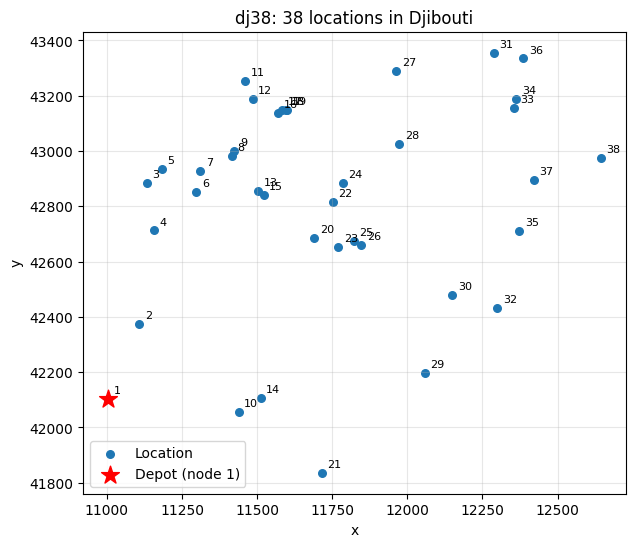

In [ ]:
xs = [coords[i][0] for i in coords]
ys = [coords[i][1] for i in coords]
plt.figure(figsize=(7, 6))
plt.scatter(xs, ys, s=30, label="Location")
plt.scatter(*coords[DEPOT], s=180, c="red", marker="*", label="Depot (node 1)", zorder=3)
for i, (x, y) in coords.items():
    plt.annotate(str(i), (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
plt.title("dj38: 38 locations in Djibouti")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 2. Distance matrix (EUC_2D) and tour validation

In [ ]:
IDS = sorted(coords)                 # 1..38
NON_DEPOT = [i for i in IDS if i != DEPOT]   # 37 IDs

# dist[i][j] with 1-based indexing
dist = np.zeros((N + 1, N + 1), dtype=np.int64)
for i in IDS:
    for j in IDS:
        xi, yi = coords[i]; xj, yj = coords[j]
        dist[i, j] = int(math.sqrt((xi - xj) ** 2 + (yi - yj) ** 2) + 0.5)
D = dist.tolist()                    # plain lists are faster in pure-Python loops

def tour_length(tour, D=D):
    return sum(D[tour[k]][tour[k + 1]] for k in range(len(tour) - 1))

def check_tour(tour):
    assert tour[0] == DEPOT and tour[-1] == DEPOT, "tour must start and end at depot 1"
    inner = tour[1:-1]
    assert len(inner) == N - 1, "must visit 37 non-depot nodes"
    assert sorted(inner) == NON_DEPOT, "each non-depot node exactly once"
    return True

def to_tour(chrom):
    # chromosome = permutation of the 37 non-depot IDs -> closed tour
    return [DEPOT] + list(chrom) + [DEPOT]

print("Distance matrix symmetric:", bool((dist == dist.T).all()))
print("Example edge 1 -> 2:", D[1][2])

Distance matrix symmetric: True
Example edge 1 -> 2: 291


## 3. Nearest Neighbor baseline
From node 1, repeatedly move to the closest unvisited node; ties go to the smaller ID.

In [ ]:
def nearest_neighbor(D, start=DEPOT):
    unvisited = set(NON_DEPOT)
    tour = [start]
    cur = start
    while unvisited:
        nxt = min(unvisited, key=lambda j: (D[cur][j], j))   # tie -> smaller ID
        tour.append(nxt)
        unvisited.remove(nxt)
        cur = nxt
    tour.append(start)
    return tour

nn_tour = nearest_neighbor(D)
nn_len = tour_length(nn_tour)
print("Valid:", check_tour(nn_tour))
print("NN tour:", nn_tour)
print("NN length:", nn_len)

Valid: True
NN tour: [1, 2, 4, 3, 5, 7, 6, 8, 9, 13, 15, 20, 23, 25, 26, 22, 24, 28, 27, 31, 36, 34, 33, 37, 35, 32, 30, 29, 21, 14, 10, 16, 17, 18, 19, 12, 11, 38, 1]
NN length: 9745


## 4. Genetic algorithm
Every individual in generation 0 and in each of the 120 new populations is scored:

80 + 120 × 80 = **9,680 evaluations per run**.

In [ ]:
def tournament(pop, fits, k, rng):
    best = None
    for idx in rng.sample(range(len(pop)), k):
        if best is None or fits[idx] < fits[best]:
            best = idx
    return pop[best]

def ordered_crossover(p1, p2, rng):
    n = len(p1)
    a, b = sorted(rng.sample(range(n), 2))
    child = [None] * n
    child[a:b + 1] = p1[a:b + 1]
    taken = set(child[a:b + 1])
    fill = [g for g in p2 if g not in taken]
    pos = 0
    for i in range(n):
        if child[i] is None:
            child[i] = fill[pos]; pos += 1
    return child

def swap_mutation(chrom, pm, rng):
    if rng.random() < pm:
        i, j = rng.sample(range(len(chrom)), 2)
        chrom[i], chrom[j] = chrom[j], chrom[i]
    return chrom

def fitness(chrom, D=D):
    total = D[DEPOT][chrom[0]] + D[chrom[-1]][DEPOT]
    for k in range(len(chrom) - 1):
        total += D[chrom[k]][chrom[k + 1]]
    return total

def genetic_algorithm(D, pop_size=80, generations=120, tsize=3, pc=0.90, pm=0.25,
                      elites=2, seed=None, nn_seed=False):
    rng = random.Random(seed)
    pop = [rng.sample(NON_DEPOT, len(NON_DEPOT)) for _ in range(pop_size)]
    if nn_seed:
        # greedy tour is built inside the timed search; remove both depot entries
        pop[0] = nearest_neighbor(D)[1:-1]
    fits = [fitness(c, D) for c in pop]
    evals = pop_size
    best_i = min(range(pop_size), key=fits.__getitem__)
    best_chrom, best_fit = pop[best_i][:], fits[best_i]
    history = [best_fit]                       # best-so-far, generation 0

    for _ in range(generations):
        order = sorted(range(pop_size), key=fits.__getitem__)
        new_pop = [pop[i][:] for i in order[:elites]]          # elitism
        while len(new_pop) < pop_size:
            p1 = tournament(pop, fits, tsize, rng)
            p2 = tournament(pop, fits, tsize, rng)
            if rng.random() < pc:
                c1 = ordered_crossover(p1, p2, rng)
                c2 = ordered_crossover(p2, p1, rng)
            else:
                c1, c2 = p1[:], p2[:]
            new_pop.append(swap_mutation(c1, pm, rng))
            if len(new_pop) < pop_size:
                new_pop.append(swap_mutation(c2, pm, rng))
        pop = new_pop
        fits = [fitness(c, D) for c in pop]
        evals += pop_size
        gi = min(range(pop_size), key=fits.__getitem__)
        if fits[gi] < best_fit:
            best_fit, best_chrom = fits[gi], pop[gi][:]
        history.append(best_fit)

    return to_tour(best_chrom), best_fit, history, evals

In [ ]:
# Quick sanity run of both variants (seed 0)
for name, seeded in [("Default GA", False), ("NN-seeded GA", True)]:
    t, L, h, ev = genetic_algorithm(D, seed=0, nn_seed=seeded)
    check_tour(t)
    assert L == tour_length(t)
    print(f"{name:13s} length={L}  evaluations={ev}  valid=True")

Default GA    length=10908  evaluations=9680  valid=True
NN-seeded GA  length=8130  evaluations=9680  valid=True


## 5. Grid search for the NN-seeded GA
All 9 pairs of mutation rate × tournament size, seeds 1, 2, 3. Population 80, 120 generations,
`pc = 0.90`, 2 elites. Selection rule: lowest mean length → lower mutation rate → smaller tournament.

In [ ]:
MUT_RATES = [0.10, 0.25, 0.40]
TSIZES = [2, 3, 5]
TUNE_SEEDS = [1, 2, 3]

rows = []
for pm, k in itertools.product(MUT_RATES, TSIZES):
    lens = []
    for s in TUNE_SEEDS:
        t, L, _, ev = genetic_algorithm(D, tsize=k, pm=pm, seed=s, nn_seed=True)
        check_tour(t); assert ev == 9680 and L == tour_length(t)
        lens.append(L)
    rows.append({"mutation_rate": pm, "tournament_size": k,
                 "seed 1": lens[0], "seed 2": lens[1], "seed 3": lens[2],
                 "mean": np.mean(lens)})

grid = pd.DataFrame(rows)
grid_sorted = grid.sort_values(["mean", "mutation_rate", "tournament_size"]).reset_index(drop=True)
best_pm = float(grid_sorted.loc[0, "mutation_rate"])
best_k = int(grid_sorted.loc[0, "tournament_size"])
print(f"Selected: mutation rate = {best_pm}, tournament size = {best_k}")
grid_sorted

Selected: mutation rate = 0.4, tournament size = 3


,mutation_rate,tournament_size,seed 1,seed 2,seed 3,mean
0,0.40,3,8124,8130,8130,8128.000
1,0.25,2,8130,8130,8130,8130.000
2,0.25,3,8130,8130,8130,8130.000
3,0.25,5,8130,8130,8130,8130.000
4,0.40,5,8130,8130,8130,8130.000
5,0.10,3,8133,8130,8134,8132.333
6,0.40,2,8170,8130,8130,8143.333
7,0.10,5,8131,8172,8131,8144.667
8,0.10,2,8175,8133,8169,8159.000


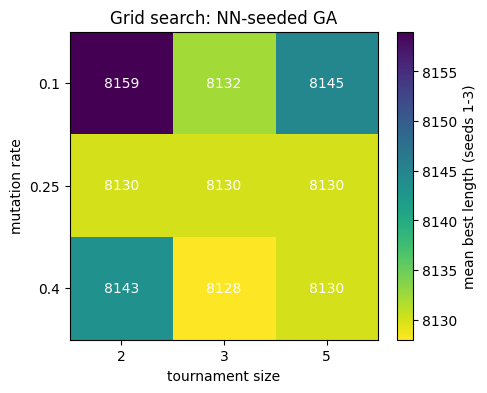

In [ ]:
pivot = grid.pivot(index="mutation_rate", columns="tournament_size", values="mean")
plt.figure(figsize=(5, 4))
plt.imshow(pivot.values, cmap="viridis_r")
plt.colorbar(label="mean best length (seeds 1-3)")
plt.xticks(range(3), pivot.columns); plt.yticks(range(3), pivot.index)
plt.xlabel("tournament size"); plt.ylabel("mutation rate")
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{pivot.values[i, j]:.0f}", ha="center", va="center", color="white")
plt.title("Grid search: NN-seeded GA")
plt.show()

## 6. Final comparison (seeds 4, 5, 6)


In [ ]:
FINAL_SEEDS = [4, 5, 6]
variants = {
    "Default GA":         dict(nn_seed=False, tsize=3, pm=0.25),
    "NN-seeded GA":       dict(nn_seed=True,  tsize=3, pm=0.25),
    "Tuned NN-seeded GA": dict(nn_seed=True,  tsize=best_k, pm=best_pm),
}

results = {}
for name, cfg in variants.items():
    runs = []
    for s in FINAL_SEEDS:
        t0 = time.perf_counter()
        tour, L, hist, ev = genetic_algorithm(D, seed=s, **cfg)
        elapsed = time.perf_counter() - t0
        check_tour(tour); assert L == tour_length(tour) and ev == 9680
        runs.append(dict(seed=s, length=L, time=elapsed, tour=tour, history=hist))
    results[name] = runs

t0 = time.perf_counter()
nn_final = nearest_neighbor(D)
nn_time = time.perf_counter() - t0
check_tour(nn_final)
nn_final_len = tour_length(nn_final)

table = [{"Method": "Nearest Neighbor", "Settings": "Depot 1",
          "Best length": nn_final_len, "Mean length": nn_final_len, "Mean time (s)": nn_time}]
settings = {"Default GA": "Random start", "NN-seeded GA": "Default settings",
            "Tuned NN-seeded GA": f"mutation rate {best_pm}, tournament size {best_k}"}
for name, runs in results.items():
    lens = [r["length"] for r in runs]
    table.append({"Method": name, "Settings": settings[name],
                  "Best length": min(lens), "Mean length": np.mean(lens),
                  "Mean time (s)": np.mean([r["time"] for r in runs])})
final_table = pd.DataFrame(table)

per_run = pd.DataFrame([{"Method": n, "Seed": r["seed"], "Length": r["length"], "Time (s)": r["time"]}
                        for n, runs in results.items() for r in runs])
display(per_run.style.format({"Time (s)": "{:.4f}"}))
final_table.style.format({"Mean length": "{:.1f}", "Mean time (s)": "{:.4f}"})

,Method,Seed,Length,Time (s)
0,Default GA,4,10461,0.1470
1,Default GA,5,10653,0.1500
2,Default GA,6,9615,0.1414
3,NN-seeded GA,4,8131,0.1504
4,NN-seeded GA,5,8130,0.1497
5,NN-seeded GA,6,8130,0.1403
6,Tuned NN-seeded GA,4,8130,0.1427
7,Tuned NN-seeded GA,5,8130,0.1455
8,Tuned NN-seeded GA,6,8130,0.1470


,Method,Settings,Best length,Mean length,Mean time (s)
0,Nearest Neighbor,Depot 1,9745,9745.0,0.0003
1,Default GA,Random start,9615,10243.0,0.1461
2,NN-seeded GA,Default settings,8130,8130.3,0.1468
3,Tuned NN-seeded GA,"mutation rate 0.4, tournament size 3",8130,8130.0,0.1451


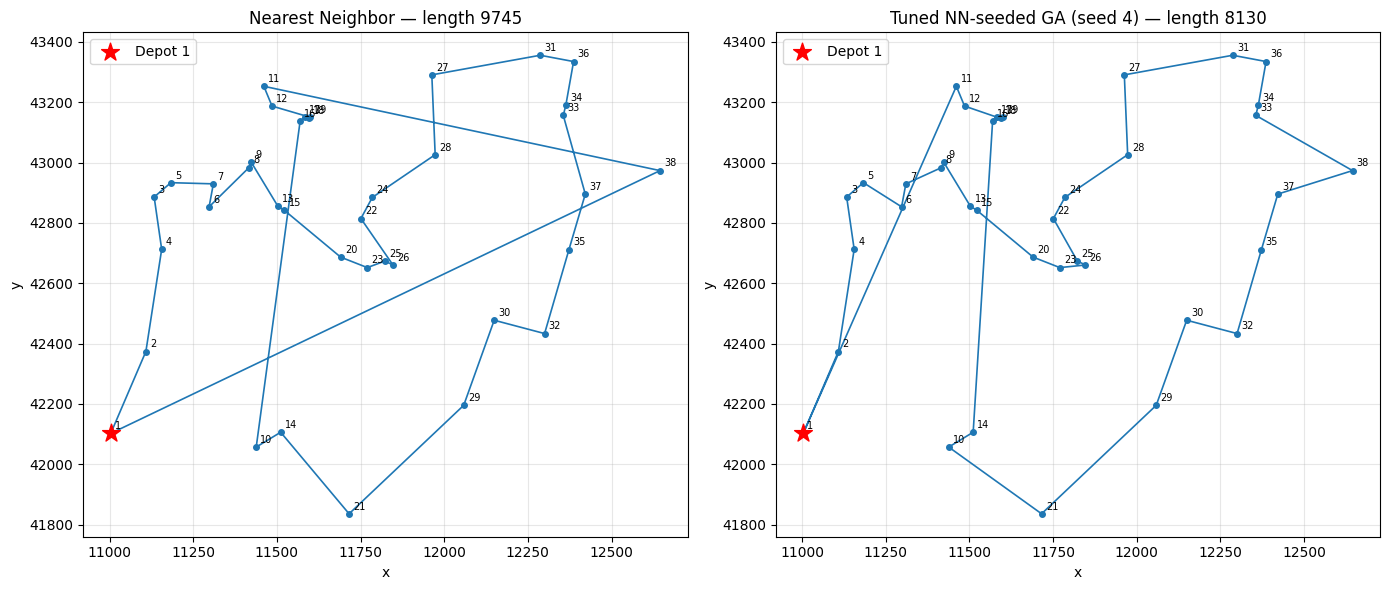

Best tuned tour: [1, 2, 4, 3, 5, 6, 7, 8, 9, 13, 15, 20, 23, 26, 25, 22, 24, 28, 27, 31, 36, 34, 33, 38, 37, 35, 32, 30, 29, 21, 10, 14, 16, 19, 18, 17, 12, 11, 1]


In [ ]:
best_tuned = min(results["Tuned NN-seeded GA"], key=lambda r: r["length"])

def plot_tour(ax, tour, title):
    px = [coords[i][0] for i in tour]; py = [coords[i][1] for i in tour]
    ax.plot(px, py, "-o", ms=4, lw=1.2)
    ax.scatter(*coords[DEPOT], s=180, c="red", marker="*", zorder=3, label="Depot 1")
    for i in IDS:
        ax.annotate(str(i), coords[i], textcoords="offset points", xytext=(3, 3), fontsize=7)
    ax.set_title(title); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.grid(alpha=0.3); ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_tour(axes[0], nn_final, f"Nearest Neighbor — length {nn_final_len}")
plot_tour(axes[1], best_tuned["tour"],
          f"Tuned NN-seeded GA (seed {best_tuned['seed']}) — length {best_tuned['length']}")
plt.tight_layout(); plt.show()
print("Best tuned tour:", best_tuned["tour"])

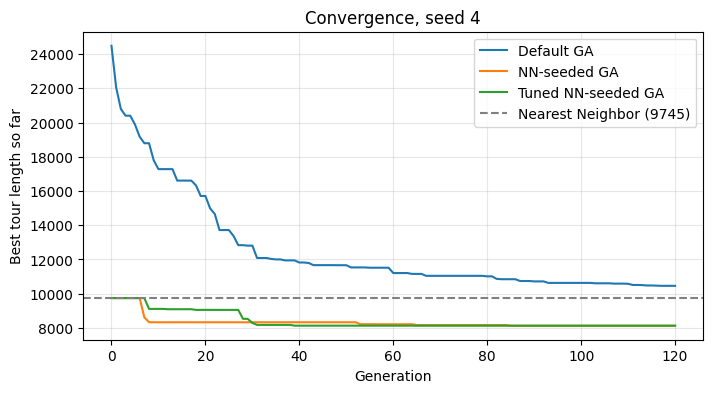

In [ ]:
plt.figure(figsize=(8, 4))
for name, runs in results.items():
    h = next(r for r in runs if r["seed"] == 4)["history"]
    plt.plot(range(len(h)), h, label=name)
plt.axhline(nn_final_len, ls="--", c="gray", label=f"Nearest Neighbor ({nn_final_len})")
plt.xlabel("Generation"); plt.ylabel("Best tour length so far")
plt.title("Convergence, seed 4"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 7. Conclusion
Почему default GA слабый. Стартует со случайных маршрутов длиной ~24 000. За 120 поколений (9680 оценок) успевает дойти только до ~10 000 и всё ещё улучшается. Бюджета мало для 37! вариантов.

Почему seeding так помог. С первого поколения в популяции есть хороший маршрут 9745. Элитизм его сохраняет, турнир часто выбирает его родителем. OX и swap чинят его длинные рёбра (11 → 38 → 1). Уже к ~10–30 поколению длина ~8300.
Почему tuning почти не помог. Вся популяция быстро становится потомками NN-маршрута — разнообразие пропадает (premature convergence). Почти все настройки застревают в одном локальном оптимуме 8130. Высокая мутация 0.40 чуть больше исследует и один раз нашла 8124. Хуже всего pm 0.10 и k 2: мало исследования и слабое давление отбора.

Почему далеко от оптимума 6656. Swap — слабая мутация для TSP: она меняет 4 ребра наугад и не умеет «разворачивать» сегменты и убирать пересечения. На маршруте 8130 видны пересекающиеся линии (например, 14 → 16). Улучшения: inversion mutation или 2-opt local search, больше поколений, больше популяция.
Время. NN — меньше миллисекунды, O(n²) ≈ 1400 операций. Все GA — ~0.1 с, в сотни раз медленнее, но примерно одинаково между собой: у всех ровно 9680 оценок. Построение NN внутри seeded GA почти ничего не добавляет.

